# Uniform and distance weights

In [k-nearest neighbours](../knn.ipynb), each of the *k* neighbours has one vote. With `weights="distance"`, each votes with a weight of one divided by its distance, so the closer neighbours count more. The difference is easiest to see in the decision boundary.

Adapted from scikit-learn's example *Nearest Neighbors Classification* (BSD-3-Clause licence, © the scikit-learn developers).

## The data

The iris flowers, with only the length and width of their sepals, so that the boundary can be drawn in two dimensions:

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris(as_frame=True)
X = iris.data[["sepal length (cm)", "sepal width (cm)"]]
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)

## Two classifiers

The same pipeline, a scaler and 11 neighbours, with each setting of `weights`. The background colour is the class each classifier would predict at that point; the dots are the training flowers:

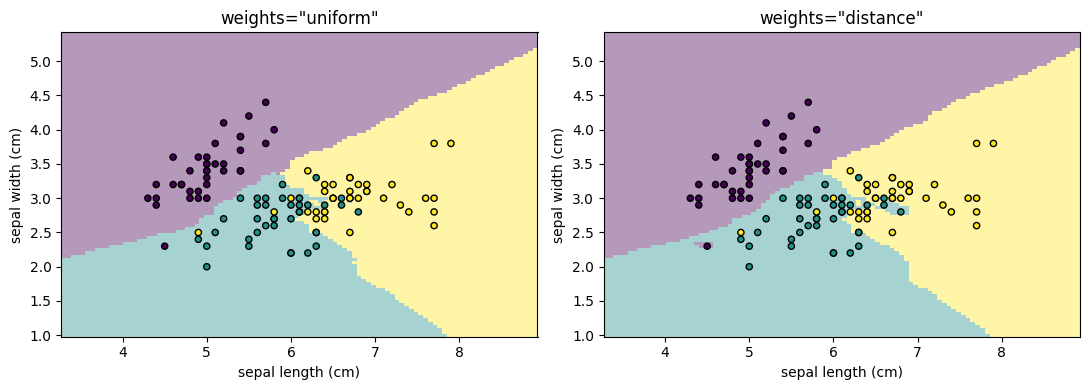

In [ ]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

classifiers = {
    weights: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11, weights=weights)).fit(X_train, y_train)
    for weights in ("uniform", "distance")
}
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, (weights, classifier) in zip(axes, classifiers.items()):
    DecisionBoundaryDisplay.from_estimator(classifier, X_train, response_method="predict", plot_method="pcolormesh",
                                           shading="auto", alpha=0.4, ax=axis,
                                           multiclass_colors="viridis")  # the colours of the points
    axis.scatter(X_train.iloc[:, 0], X_train.iloc[:, 1], c=y_train, edgecolors="k", s=20)
    axis.set_title(f'weights="{weights}"')
figure.tight_layout()

With uniform weights, the regions are broad and their borders fairly smooth: a prediction is the majority of 11 votes. With distance weights, the borders bend around single training points, and small islands appear around flowers surrounded by another species: close to a training point, that point's weight dominates the vote.

## Training accuracy says little here

In [ ]:
import pandas as pd

pd.DataFrame({
    weights: {"training accuracy": classifier.score(X_train, y_train), "test accuracy": classifier.score(X_test, y_test)}
    for weights, classifier in classifiers.items()
}).round(3)

,uniform,distance
training accuracy,0.866,0.946
test accuracy,0.711,0.632


With distance weights, a training flower is its own nearest neighbour, at distance 0, and one divided by zero outweighs any other vote (scikit-learn gives the neighbours at distance 0 the whole vote). So 95% of the training flowers are predicted correctly, against 87% with uniform weights; the 6 that aren't share their exact measurements with a training flower of another species. That training accuracy reflects only the setting, and says nothing about new flowers: on the test flowers, distance weights do *worse* here, 0.63 against 0.71. As in [Overfitting and the train/test split](../../../ml-fundamentals/overfitting_and_the_split.ipynb), the comparison has to be made on data the model didn't see. Which setting is better depends on the data, so `weights`, like *k*, is a setting to choose by validation ([Cross-validation and hyperparameter search](../../../ml-fundamentals/cross_validation_and_search.ipynb)).